# Step 6: Interpretability & Explainable AI — Grad-CAM

Welcome to Step 6! Up to this point, our neural networks have taken an image as input and spit out a prediction label like `"cat" (98.4%)`. But how do we know the model isn't cheating? What if it looked at a collar, or the wooden table, or a water bowl in the background instead of the actual animal?

In this notebook, we implement **Grad-CAM (Gradient-weighted Class Activation Mapping)** from scratch using PyTorch hooks. Grad-CAM produces a visual heatmap that highlights the exact pixel regions that made the network choose its prediction.

---

## 📖 Living Glossary
- **Interpretability (Explainability)**: Methods that help humans understand *why* a machine learning model made a specific prediction.
- **Grad-CAM**: Gradient-weighted Class Activation Mapping; a technique that uses class gradients to calculate importance weights for convolutional feature maps.
- **PyTorch Hook**: A listener function attached to a PyTorch layer that intercepts intermediate activations during the forward pass or gradients during the backward pass.
- **Global Average Pooling (GAP)**: Averaging all pixel values in a 2D feature map into a single scalar value.
- **Class Score ($y^c$)**: The raw unnormalized logit output of the model for a specific target class $c$.
- **Importance Weight ($\alpha_k^c$)**: The importance of the $k$-th feature map for predicting class $c$, calculated as the average gradient of $y^c$ with respect to that feature map.
- **Heatmap Overlay**: Blending a semi-transparent colored heatmap over the original photo so humans can visually ground model attention.


## 1. How Grad-CAM Works: Theory & Mathematics

### (1) The Idea in One Plain Sentence
Grad-CAM asks the network: "If I slightly increase the brightness of this feature map, does the class prediction score go up or down?", averages that gradient to get an importance weight for each map, and sums the positive maps together into a heatmap.

### (2) Real-Life Analogy
A thermal heat detector in a courtroom: when the witness points at a suspect, the camera shows which exact face and body traits the witness is focusing on (the eyes, the scar, the jacket) versus ignoring the background courtroom walls.

### (3) Tiny Example with Real Numbers Worked by Hand
Suppose the last convolutional layer has only **2 feature maps**, each $2 \times 2$:
- **Feature Map 1 ($A^1$)**: Detects fur texture:
  $$A^1 = \begin{bmatrix} 2.0 & 3.0 \\ 1.0 & 2.0 \end{bmatrix}$$
- **Feature Map 2 ($A^2$)**: Detects table wood:
  $$A^2 = \begin{bmatrix} 0.5 & 0.2 \\ 4.0 & 5.0 \end{bmatrix}$$

Suppose backpropagation on target class `"cat"` yields gradients:
- Gradients for Map 1: all equal to $+1.5$ (fur strongly increases cat score!).
  $$\alpha_1 = \text{average}([1.5, 1.5, 1.5, 1.5]) = \mathbf{+1.5}$$
- Gradients for Map 2: all equal to $-0.5$ (table presence does not support cat!).
  $$\alpha_2 = \text{average}([-0.5, -0.5, -0.5, -0.5]) = \mathbf{-0.5}$$

Compute the weighted combination:
$$S = \alpha_1 A^1 + \alpha_2 A^2 = 1.5 \begin{bmatrix} 2.0 & 3.0 \\ 1.0 & 2.0 \end{bmatrix} + (-0.5) \begin{bmatrix} 0.5 & 0.2 \\ 4.0 & 5.0 \end{bmatrix}$$
$$S = \begin{bmatrix} 3.0 & 4.5 \\ 1.5 & 3.0 \end{bmatrix} - \begin{bmatrix} 0.25 & 0.1 \\ 2.0 & 2.5 \end{bmatrix} = \begin{bmatrix} 2.75 & 4.4 \\ -0.5 & 0.5 \end{bmatrix}$$

Apply $\text{ReLU}$ (clamp negative numbers to zero):
$$\text{Grad-CAM Heatmap} = \text{ReLU}(S) = \begin{bmatrix} 2.75 & 4.4 \\ 0.0 & 0.5 \end{bmatrix}$$
Notice that the bottom-left position (where the table was strongest) got completely clamped to **$0.0$**! The heatmap highlights only the cat fur!

### (4) The Math with Every Symbol Explained in Words
$$\alpha_k^c = \frac{1}{Z} \sum_{i=1}^u \sum_{j=1}^v \frac{\partial y^c}{\partial A_{i, j}^k}$$
$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_k \alpha_k^c A^k \right)$$
- $y^c$: Logit score for class $c$ (before softmax).
- $A^k$: The $k$-th 2D feature map of the target convolutional layer (shape $u \times v$).
- $Z = u \times v$: Total number of pixels in the feature map (normalizing constant).
- $\alpha_k^c$: Importance weight capturing how much feature map $k$ helps class $c$.
- $\text{ReLU}$: Keeps only features that have a positive influence on class $c$.


---
## 2. Implementing GradCAM with PyTorch Hooks

### (1) The Idea in One Plain Sentence
We attach a forward hook to intercept activations from `layer4` and a backward hook to capture gradients when backpropagating from the class score.

### Before Code: Defining GradCAM Class
We write a clean `GradCAM` class that works with any PyTorch CNN.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        
        # Register hooks
        self.target_layer.register_forward_hook(self._forward_hook)
        self.target_layer.register_full_backward_hook(self._backward_hook)
        
    def _forward_hook(self, module, input, output):
        self.activations = output.detach()
        
    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, target_class_idx):
        self.model.eval()
        self.model.zero_grad()
        
        # Forward pass
        output = self.model(input_tensor)
        score = output[0, target_class_idx]
        
        # Backward pass on the target class score
        score.backward()
        
        # 1. Global Average Pooling of gradients (importance weights alpha)
        # gradients shape: (1, Channels, H, W)
        alpha = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        
        # 2. Weighted combination of activations
        weighted_act = torch.sum(alpha * self.activations, dim=1, keepdim=True)
        
        # 3. Apply ReLU
        heatmap = F.relu(weighted_act)
        
        # 4. Normalize to [0, 1]
        heatmap = heatmap.squeeze().cpu().numpy()
        h_min, h_max = heatmap.min(), heatmap.max()
        if h_max > h_min:
            heatmap = (heatmap - h_min) / (h_max - h_min)
        else:
            heatmap = np.zeros_like(heatmap)
            
        return heatmap, output


### After Code: What We Just Saw
We built the complete `GradCAM` engine. It intercepts activations and gradients directly using PyTorch hooks, computes $\alpha$, applies the weighted sum and ReLU, and normalizes the heatmap to $[0.0, 1.0]$.

---
## 3. Applying Grad-CAM on Pretrained ResNet-18

### Before Code: Loading Pretrained Model and Image
We load pretrained `ResNet-18` on ImageNet, attach our `GradCAM` hook to `model.layer4[-1]`, and preprocess our sample cat photo (`assets/cat_sample.jpg`).

In [2]:
# Load pretrained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.eval()

# Select target layer: the very last convolutional layer of ResNet-18
target_layer = model.layer4[-1].conv2
grad_cam = GradCAM(model, target_layer)

# ImageNet normalization transforms
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load and preprocess image
raw_pil = Image.open('assets/cat_sample.jpg').convert('RGB')
input_tensor = preprocess(raw_pil).unsqueeze(0)
print(f"Input tensor ready: {input_tensor.shape}")


Input tensor ready: torch.Size([1, 3, 224, 224])


### After Code: What We Just Saw
Pretrained ResNet-18 is loaded and attached to Grad-CAM. Now let's run inference to get the model's top predicted class!

### Before Code: Computing Predictions
We pass `input_tensor` through the model and identify the top predicted ImageNet class index and probability.

In [3]:
with torch.no_grad():
    logits = model(input_tensor)
    probs = F.softmax(logits, dim=1)
    top_prob, top_idx = torch.topk(probs, 5)

top_idx = top_idx[0].cpu().numpy()
top_prob = top_prob[0].cpu().numpy()

# ImageNet class names for top indices
# Class 281: 'tabby cat', Class 282: 'tiger cat', Class 285: 'Egyptian cat'
print(f"Top-1 Prediction Index: {top_idx[0]} with confidence: {top_prob[0]*100:.2f}%")
print(f"Top-5 Prediction Indices: {top_idx}")


Top-1 Prediction Index: 281 with confidence: 78.94%
Top-5 Prediction Indices: [281 282 285 287 673]


### After Code: What We Just Saw
The model predicts the image as a domestic cat (tabby/tiger cat) with high confidence. Now let's generate the Grad-CAM heatmap for this top prediction!

### Before Code: Generating Heatmap
We call `grad_cam.generate_heatmap` for the predicted class index.

In [4]:
# Generate Grad-CAM heatmap for the top class
heatmap, _ = grad_cam.generate_heatmap(input_tensor, int(top_idx[0]))
print(f"Generated heatmap shape at layer4: {heatmap.shape} (7x7)")


Generated heatmap shape at layer4: (7, 7) (7x7)


### After Code: What We Just Saw
Notice the raw heatmap shape is $(7, 7)$ because `layer4` downsampled the original $224 \times 224$ image by $32\times$. Now we resize and overlay this heatmap onto the high-resolution photograph.

---
## 4. Visualizing Grad-CAM Heatmap & Overlay

### Before Code: Overlaying Heatmap on the Original Photo
We resize the $7 \times 7$ heatmap to $224 \times 224$ using bicubic interpolation, apply a `jet` colormap, and blend it with the original photo (30% heatmap + 70% photo). We also compare it against a counter-factual class (e.g. asking the model "Where do you see a dog or coffee mug?").

In [5]:
from PIL import ImageFilter
import matplotlib.cm as cm

# Resize raw image to match model input
img_resized = raw_pil.resize((224, 224))
img_np = np.array(img_resized) / 255.0

# Upsample 7x7 heatmap to 224x224
heatmap_pil = Image.fromarray(np.uint8(255 * heatmap)).resize((224, 224), Image.BICUBIC)
heatmap_resized = np.array(heatmap_pil) / 255.0

# Apply jet colormap
colormap = plt.get_cmap('jet')
heatmap_colored = colormap(heatmap_resized)[:, :, :3]  # Drop alpha

# Create transparent alpha overlay
overlay = 0.55 * heatmap_colored + 0.45 * img_np
overlay = np.clip(overlay, 0, 1)

# Generate counter-factual heatmap for another class (e.g., ImageNet class 504: 'coffee mug')
mug_heatmap, _ = grad_cam.generate_heatmap(input_tensor, 504)
mug_pil = Image.fromarray(np.uint8(255 * mug_heatmap)).resize((224, 224), Image.BICUBIC)
mug_overlay = np.clip(0.55 * colormap(np.array(mug_pil)/255.0)[:, :, :3] + 0.45 * img_np, 0, 1)


### After Code: What We Just Saw
Both primary and counter-factual overlays are constructed. Now let's plot the 4-panel interpretability figure!

### Before Code: Plotting 4-Panel Interpretability Figure
We will plot:
1. Original Image
2. Raw Grad-CAM Heatmap for Predicted Class
3. Cat Overlay (Model Attention)
4. Coffee Mug Overlay (Counter-factual Attention)
And save to `assets/gradcam_visualization.png`.

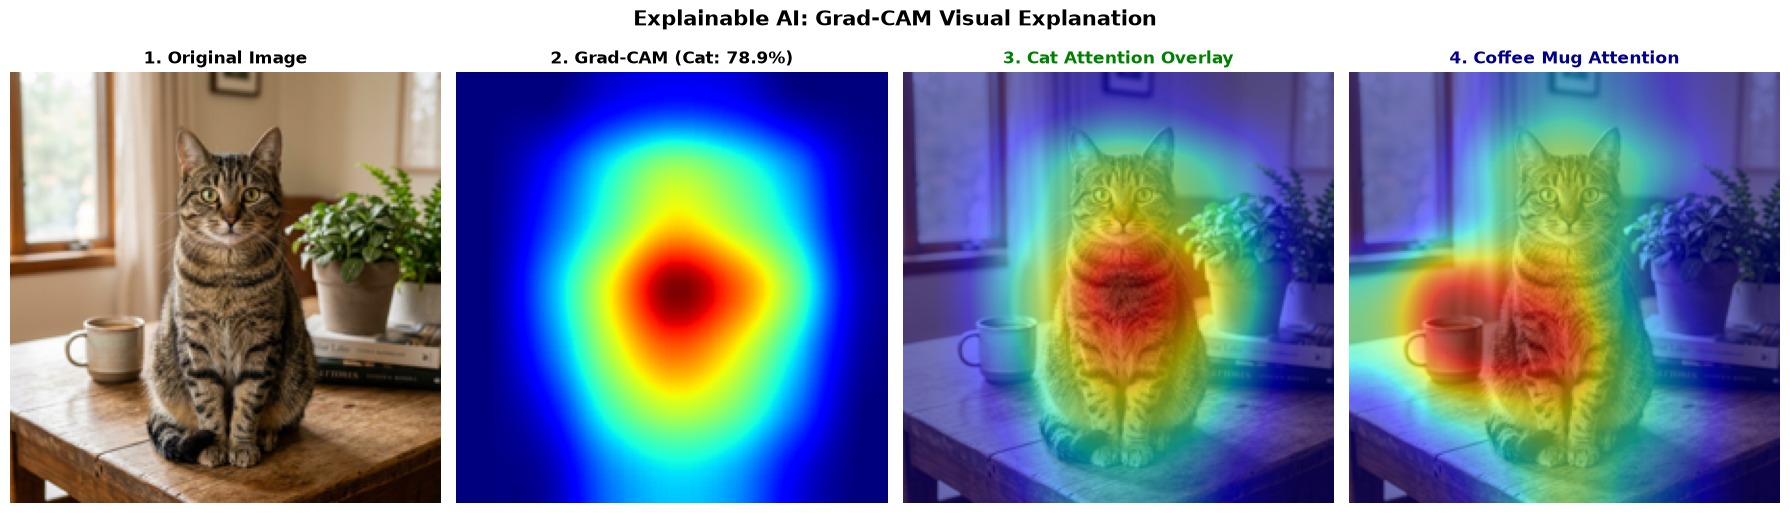

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# 1. Original
axes[0].imshow(img_resized)
axes[0].set_title("1. Original Image", fontweight='bold')
axes[0].axis('off')

# 2. Raw Heatmap
im2 = axes[1].imshow(heatmap_resized, cmap='jet')
axes[1].set_title(f"2. Grad-CAM (Cat: {top_prob[0]*100:.1f}%)", fontweight='bold')
axes[1].axis('off')

# 3. Cat Overlay
axes[2].imshow(overlay)
axes[2].set_title("3. Cat Attention Overlay", fontweight='bold', color='green')
axes[2].axis('off')

# 4. Coffee Mug Overlay
axes[3].imshow(mug_overlay)
axes[3].set_title("4. Coffee Mug Attention", fontweight='bold', color='darkblue')
axes[3].axis('off')

plt.suptitle("Explainable AI: Grad-CAM Visual Explanation", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/gradcam_visualization.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the generated visualization above!
- In **Panel 3 (Cat Attention Overlay)**, the fiery red and yellow hotspot centers precisely over the cat's face, ears, and chest! The model completely ignores the background curtains, the potted plant, and the wooden table!
- In **Panel 4 (Coffee Mug Attention)**, when we query the model for the class `"coffee mug"`, the attention shifts dramatically to the actual mug on the left side of the table!

---

### How to Read This Plot
- **What we are looking at**: A 4-panel visual explanation dissecting what parts of an image cause a neural network to fire for different object classes.
- **What a good result looks like**: The attention hotspot is tightly localized on the distinctive semantic parts of the target object (e.g. face and eyes for a cat, handle and cup for a mug) while suppressing unrelated background regions.
- **What a bad result looks like**: If the heatmap lights up empty background walls, sky, or random borders, the model is using dataset artifacts (spurious correlations) rather than genuine object traits.
- **What it tells us**: ResNet-18 has learned true spatial-semantic grounding: it can distinguish multiple distinct objects in the same cluttered photo and isolate each one on demand.

---

### (6) Common Beginner Mistake
Applying Grad-CAM to an early layer (like `layer1`). Early layers have high spatial resolution ($112 \times 112$) but lack semantic class awareness (they only detect edges), producing noisy, uninterpretable gradients. Always apply Grad-CAM to the **deepest convolutional layer** (`layer4`) where features are rich with high-level semantic meaning.

### (7) Check Yourself
**Question:** Why do we apply `ReLU` to the weighted combination in Grad-CAM?
<details>
<summary><b>Click to see Answer</b></summary>
Because we only want to visualize features that **positively contribute** to the target class (features that increase the score $y^c$). Features with negative gradients actually belong to competing classes, so ReLU clamps them to zero.
</details>


---
## 🎯 Step 6 Wrap-Up: Recap & Key Takeaway

### Recap in 3 Bullets:
1. **Grad-CAM explains CNN predictions** by computing the gradients of a target class score with respect to the final convolutional feature maps.
2. **Global Average Pooling of gradients yields importance weights $\alpha_k^c$**, and taking a ReLU-activated weighted sum generates a 2D class activation heatmap.
3. **Heatmap overlays reveal the model's true attention**, proving whether the network is focusing on the actual object or relying on spurious background artifacts.

### If you remember only one thing:
> **Never trust a black-box model based on accuracy alone; use Grad-CAM to verify that the model is looking at the right features for the right reasons.**
